In [1]:
from dataclasses import dataclass, replace
from pathlib import Path
import math

from numba import njit, prange
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.signal import spectrogram, welch

mpl.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "figure.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "lines.linewidth": 1.5,
    "savefig.dpi": 400,
})

GRAVITY = 9.81                 # m/s²
WATER_DENSITY = 1025.0         # kg/m³
PRESSURE_REFERENCE = 1e-6      # Pa (1 µPa)

@dataclass(frozen=True)
class ShipParameters:
    speed_mps: float
    beam_m: float
    length_m: float
    draft_m: float

    def __post_init__(self):
        values = (self.speed_mps, self.beam_m, self.length_m, self.draft_m)
        if any(value <= 0 for value in values):
            raise ValueError("All ship parameters must be positive.")

@dataclass(frozen=True)
class PlaneParameters:
    width_m: float
    height_m: float
    pixels_per_meter: float
    center_xy_m: tuple[float, float] = (0.0, 0.0)

    def __post_init__(self):
        if self.width_m <= 0 or self.height_m <= 0:
            raise ValueError("Plane width and height must be positive.")
        if self.pixels_per_meter <= 0:
            raise ValueError("pixels_per_meter must be positive.")

@dataclass(frozen=True)
class AngularParameters:
    n_theta: int = 1000
    start_angle_deg: float = 0.0
    cutoff_angle_deg: float = 0.0

    def __post_init__(self):
        end_angle_deg = 90.0 - self.cutoff_angle_deg
        if self.n_theta < 2:
            raise ValueError("n_theta must be at least 2.")
        if not 0.0 <= self.start_angle_deg < end_angle_deg <= 90.0:
            raise ValueError("Angles must satisfy 0 <= start < 90 - cutoff <= 90.")

@dataclass(frozen=True)
class ReceiverParameters:
    x_m: float
    y_m: float
    depth_m: float

    def __post_init__(self):
        if self.depth_m < 0:
            raise ValueError("Receiver depth cannot be negative.")

@dataclass(frozen=True)
class KelvinSpectrum:
    theta_rad: np.ndarray
    wavenumber_rad_per_m: np.ndarray
    kx_rad_per_m: np.ndarray
    ky_rad_per_m: np.ndarray
    elevation_weight: np.ndarray

def create_plane(
    width: float,
    height: float,
    pixels_per_meter: float,
    center_xy: tuple[float, float] = (0.0, 0.0),
) -> np.ndarray:
    """Create an ``(ny, nx, 3)`` array containing X, Y, and Z."""
    if width <= 0 or height <= 0 or pixels_per_meter <= 0:
        raise ValueError("width, height, and pixels_per_meter must be positive.")

    nx = int(round(width * pixels_per_meter)) + 1
    ny = int(round(height * pixels_per_meter)) + 1
    center_x, center_y = center_xy

    x = np.linspace(center_x - width / 2, center_x + width / 2, nx)
    y = np.linspace(center_y - height / 2, center_y + height / 2, ny)

    X, Y = np.meshgrid(x, y, indexing="xy")
    Z = np.zeros_like(X)
    return np.stack((X, Y, Z), axis=-1)

def plot_plane(
    plane: np.ndarray,
    *,
    width_cm: float = 15.5,
    height_cm: float = 9.0,
    title: str = "Sea elevation",
    colorbar_label: str = "Elevation [m]",
    tick_spacing: float = 15.0,
    cmap: str = "viridis",
    color_limits: tuple[float, float] | None = None,
    save_path: str | Path | None = None,
):
    """Plot a plane with equal spatial scale and equal X/Y tick spacing."""
    plane = np.asarray(plane, dtype=float)
    if plane.ndim != 3 or plane.shape[-1] != 3:
        raise ValueError("plane must have shape (ny, nx, 3).")

    X = plane[:, :, 0]
    Y = plane[:, :, 1]
    Z = plane[:, :, 2]

    if color_limits is None:
        maximum = float(np.nanmax(np.abs(Z)))
        maximum = maximum if maximum > 0 else 1.0
        color_limits = (-maximum, maximum)

    fig, ax = plt.subplots(figsize=(width_cm / 2.54, height_cm / 2.54))
    pcm = ax.pcolormesh(
        X,
        Y,
        Z,
        shading="auto",
        cmap=cmap,
        vmin=color_limits[0],
        vmax=color_limits[1],
    )

    ax.set_xlim(X.min(), X.max())
    ax.set_ylim(Y.min(), Y.max())
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(MultipleLocator(tick_spacing))
    ax.yaxis.set_major_locator(MultipleLocator(tick_spacing))
    ax.set_xlabel("X [m]")
    ax.set_ylabel("Y [m]")
    ax.set_title(title)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="3%", pad=0.08)
    cbar = fig.colorbar(pcm, cax=cax)
    cbar.set_label(colorbar_label)

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")

    return fig, ax, pcm

def prepare_kelvin_spectrum(
    ship: ShipParameters,
    angular: AngularParameters,
) -> KelvinSpectrum:
    """Precompute all angle-dependent terms in the Kelvin integral."""
    start = np.deg2rad(angular.start_angle_deg)
    stop = np.deg2rad(90.0 - angular.cutoff_angle_deg)

    edges = np.linspace(start, stop, angular.n_theta + 1)
    theta = 0.5 * (edges[:-1] + edges[1:])
    dtheta = edges[1] - edges[0]

    U = ship.speed_mps
    B = ship.beam_m
    L = ship.length_m
    T = ship.draft_m

    cos_theta = np.cos(theta)
    sin_theta = np.sin(theta)
    sec_theta = 1.0 / cos_theta
    k0 = GRAVITY / U**2
    k = k0 * sec_theta**2
    a = k0 * sec_theta
    b = 0.5 * a * L

    first_term = (32.0 * B * sec_theta) / (np.pi * L**2)
    draft_term = -np.expm1(-k * T)  # numerically stable 1 - exp(-kT)
    c1 = 2.0 / a**2 + 24.0 / (L**2 * a**4)
    c2 = 0.5 * L / a - 12.0 / (L * a**3)
    hull_term = c1 * np.sin(b) + c2 * np.cos(b)

    elevation_weight = first_term * draft_term * hull_term * dtheta

    return KelvinSpectrum(
        theta_rad=theta,
        wavenumber_rad_per_m=k,
        kx_rad_per_m=k * cos_theta,
        ky_rad_per_m=k * sin_theta,
        elevation_weight=elevation_weight,
    )

@njit(parallel=True, cache=True)
def kelvin_response_parallel(
    x_relative,
    y_relative,
    kx_rad_per_m,
    ky_rad_per_m,
    weights,
    ship_length_m,
    ship_speed_mps,
    kelvin_half_angle_rad,
    transition_m,
    wedge = False,
):
    response = np.zeros(x_relative.size)

    # Each CPU thread evaluates different observation points.
    for i in prange(x_relative.size):
        x = x_relative[i]
        y = abs(y_relative[i])

        # Your exact geometric damping expression
        trailing_time = (
            abs(
                (-x + 0.5 * ship_length_m)
                / ship_speed_mps
            )
            + 1.0
        )

        damping = 1.0 / math.sqrt(trailing_time)

        if wedge == True:
            # Kelvin wedge width at this longitudinal position
            wedge_half_width_m = (
                -(x - ship_length_m) * np.tan(kelvin_half_angle_rad)
            )

            # No propagating far-field wake in front of the vessel
            if x - ship_length_m>= 0.0:
                wedge_taper = 0.0

            # Fully inside the Kelvin wedge
            elif y <= wedge_half_width_m:
                wedge_taper = 1.0

            # Smooth transition across the wedge boundary
            elif y <= wedge_half_width_m + transition_m:
                wedge_taper = (
                    1.0
                    - (y - wedge_half_width_m) / transition_m
                )

            # Outside the Kelvin wedge
            else:
                wedge_taper = 0.0
        else:
            wedge_taper = 1

        value = 0.0

        # Sum all Kelvin-angle contributions for this point
        for j in range(weights.size):
            phase = (
                x * kx_rad_per_m[j]
                + y * ky_rad_per_m[j]
            )

            value += math.sin(phase) * weights[j]

        response[i] = wedge_taper * damping * value

    return response

def evaluate_kelvin_response(
    x_observer,
    y_observer,
    ship_x,
    ship_y,
    *,
    ship: ShipParameters,
    spectrum: KelvinSpectrum,
    quantity: str = "elevation",
    depth_m: float = 0.0,
    water_depth_m: float | None = None,
    chunk_size: int = 2048,
) -> np.ndarray:
    """Evaluate elevation or pressure for broadcast-compatible inputs."""

    if quantity not in {"elevation", "pressure"}:
        raise ValueError("quantity must be 'elevation' or 'pressure'.")

    if depth_m < 0:
        raise ValueError("depth_m cannot be negative.")

    if chunk_size < 1:
        raise ValueError("chunk_size must be positive.")

    x_observer, y_observer, ship_x, ship_y = np.broadcast_arrays(
        np.asarray(x_observer, dtype=float),
        np.asarray(y_observer, dtype=float),
        np.asarray(ship_x, dtype=float),
        np.asarray(ship_y, dtype=float),
    )
    wedge = True
    output_shape = x_observer.shape

    # Coordinates relative to the vessel reference position
    x_relative = np.ravel(x_observer - ship_x)
    y_relative = np.ravel(y_observer - ship_y)

    response = np.zeros(x_relative.size, dtype=float)

    if quantity == "elevation":
        wedge = False
        weights = spectrum.elevation_weight

    else:
        if water_depth_m is None:
            raise ValueError(
                "water_depth_m is required when quantity='pressure'."
            )

        if not 0.0 <= depth_m <= water_depth_m:
            raise ValueError(
                "depth_m must be between 0 and water_depth_m."
            )

        k = spectrum.wavenumber_rad_per_m
        H = water_depth_m
        d = depth_m

        depth_attenuation = (
            np.exp(-k * d)
            * (1.0 + np.exp(-2.0 * k * (H - d)))
            / (1.0 + np.exp(-2.0 * k * H))
        )

        weights = (
            WATER_DENSITY
            * GRAVITY
            * depth_attenuation
            * spectrum.elevation_weight
        )


    # Calculate every observation point in chunks.
    response = kelvin_response_parallel(
        np.ascontiguousarray(x_relative),
        np.ascontiguousarray(y_relative),
        np.ascontiguousarray(spectrum.kx_rad_per_m),
        np.ascontiguousarray(spectrum.ky_rad_per_m),
        np.ascontiguousarray(weights),
        ship.length_m,
        ship.speed_mps,
        kelvin_half_angle_rad = np.arcsin(1.0 / 3.0),
        transition_m = 3.0,
        wedge = wedge
    )

    return response.reshape(output_shape)

def simulate_plane(
    plane: np.ndarray,
    *,
    ship_xy_m: tuple[float, float],
    ship: ShipParameters,
    spectrum: KelvinSpectrum,
    quantity: str = "elevation",
    depth_m: float = 0.0,
    chunk_size: int = 2048,
) -> np.ndarray:
    """Return a copy of the plane with its Z channel filled by the model."""
    result = np.asarray(plane, dtype=float).copy()
    if result.ndim != 3 or result.shape[-1] != 3:
        raise ValueError("plane must have shape (ny, nx, 3).")

    result[:, :, 2] = evaluate_kelvin_response(
        result[:, :, 0],
        result[:, :, 1],
        ship_xy_m[0],
        ship_xy_m[1],
        ship=ship,
        spectrum=spectrum,
        quantity=quantity,
        depth_m=depth_m,
        chunk_size=chunk_size,
    )
    return result

def simulate_receiver(
    receiver: ReceiverParameters,
    *,
    ship: ShipParameters,
    spectrum: KelvinSpectrum,
    trajectory_start_xy_m: tuple[float, float],
    duration_s: float,
    sampling_frequency_hz: float,
    water_depth_m: float | None = None,
    chunk_size: int = 2048,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Move the vessel in +X and evaluate a fixed receiver."""
    if duration_s <= 0 or sampling_frequency_hz <= 0:
        raise ValueError("duration_s and sampling_frequency_hz must be positive.")
    
    quantity = "pressure"
    sample_count = int(round(duration_s * sampling_frequency_hz))
    time_s = np.arange(sample_count, dtype=float) / sampling_frequency_hz
    vessel_x_m = trajectory_start_xy_m[0] + ship.speed_mps * time_s
    vessel_y_m = np.full_like(time_s, trajectory_start_xy_m[1])

    response = evaluate_kelvin_response(
        receiver.x_m,
        receiver.y_m,
        vessel_x_m,
        vessel_y_m,
        ship=ship,
        spectrum=spectrum,
        quantity=quantity,
        depth_m=receiver.depth_m,
        water_depth_m = water_depth_m,
        chunk_size=chunk_size,
    )
    return time_s, response, vessel_x_m, vessel_y_m

def _single_sided_amplitude(values: np.ndarray, fs: float):
    values = np.asarray(values, dtype=float)
    frequencies = np.fft.rfftfreq(values.size, 1/fs)
    values_fft = values - np.mean(values)

    fft_values = np.fft.rfft(values_fft)

    amplitude = np.abs(fft_values) / values.size
    
    if values.size % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2
    return frequencies, amplitude

def plot_signal_analysis(
    time_s: np.ndarray,
    values: np.ndarray,
    sampling_frequency_hz: float,
    *,
    quantity: str = "pressure",
    frequency_limits_hz: tuple[float, float] = (0.05, 100.0),
    time_limits_s: tuple[float, float] | None = None,
    nperseg: int = 4096,
    spectrogram_dynamic_range_db: float = 80.0,
    width_cm: float = 15.5,
    height_cm: float = 9.0,
    save_path: str | Path | None = None,
):
    """Plot and optionally save waveform, amplitude spectrum, and spectrogram."""

    time_s = np.asarray(time_s, dtype=float)
    values = np.asarray(values, dtype=float)

    if time_s.ndim != 1 or values.ndim != 1 or time_s.size != values.size:
        raise ValueError("time_s and values must be equal-length 1D arrays.")

    if quantity not in {"elevation", "pressure"}:
        raise ValueError("quantity must be 'elevation' or 'pressure'.")

    if quantity == "pressure":
        reference_amplitude = PRESSURE_REFERENCE
        reference_psd = PRESSURE_REFERENCE**2
        value_label = "Pressure [Pa]"
        magnitude_label = "Magnitude [dB re 1 µPa]"
        spectrogram_label = "PSD [dB re 1 µPa²/Hz]"
    else:
        reference_amplitude = 1.0
        reference_psd = 1.0
        value_label = "Sea elevation [m]"
        magnitude_label = "Magnitude [dB re 1 m]"
        spectrogram_label = "PSD [dB re 1 m²/Hz]"

    # ------------------------------------------------------------
    # Calculate spectrum
    # ------------------------------------------------------------
    frequencies, amplitude = _single_sided_amplitude(
        values,
        sampling_frequency_hz,
    )

    tiny = np.finfo(float).tiny

    magnitude_db = 20.0 * np.log10(
        np.maximum(amplitude, tiny) / reference_amplitude
    )

    # ------------------------------------------------------------
    # Calculate spectrogram
    # ------------------------------------------------------------
    segment_length = min(int(nperseg), values.size)

    spec_f, spec_t, spec_psd = spectrogram(
        values,
        fs=sampling_frequency_hz,
        window="hann",
        nperseg=segment_length,
        noverlap=segment_length // 2,
        detrend="constant",
        scaling="density",
        mode="psd",
    )

    spectrogram_db = 10.0 * np.log10(
        np.maximum(spec_psd, tiny) / reference_psd
    )

    spectrogram_max_db = float(np.nanmax(spectrogram_db))
    spectrogram_min_db = (
        spectrogram_max_db - spectrogram_dynamic_range_db
    )

    # ------------------------------------------------------------
    # Frequency limits
    # ------------------------------------------------------------
    positive_fft = frequencies > 0
    positive_spec = spec_f > 0

    lower = max(
        frequency_limits_hz[0],
        frequencies[positive_fft].min(),
    )

    upper = min(
        frequency_limits_hz[1],
        sampling_frequency_hz / 2,
    )

    figsize = (
        width_cm / 2.54,
        height_cm / 2.54,
    )

    # ============================================================
    # 1. TIME DOMAIN
    # ============================================================

    fig_time, ax_time = plt.subplots(figsize=figsize)

    ax_time.plot(time_s, values)

    ax_time.set_title("Time domain")
    ax_time.set_xlabel("Time [s]")
    ax_time.set_ylabel(value_label)

    ax_time.set_xlim(
        time_limits_s or (time_s[0], time_s[-1])
    )
    # ax_time.set_ylim(-1,1)

    ax_time.grid(alpha=0.3)

    fig_time.tight_layout()

    # ============================================================
    # 2. AMPLITUDE SPECTRUM
    # ============================================================

    fig_fft, ax_fft = plt.subplots(figsize=figsize)

    ax_fft.semilogx(
        frequencies[positive_fft],
        magnitude_db[positive_fft],
    )

    ax_fft.set_title("Signal spectrum")
    ax_fft.set_xlabel("Frequency [Hz]")
    ax_fft.set_ylabel(magnitude_label)

    ax_fft.set_xlim(lower, upper)

    ax_fft.grid(alpha=0.3, which="both")

    fig_fft.tight_layout()

    # ============================================================
    # 3. SPECTROGRAM
    # ============================================================

    fig_spec, ax_spec = plt.subplots(figsize=figsize)

    spec_t = spec_t - spec_t[0]
    
    image = ax_spec.pcolormesh(
        spec_t + time_s[0],
        spec_f[positive_spec],
        spectrogram_db[positive_spec],
        shading="auto",
        vmin=spectrogram_min_db,
        vmax=spectrogram_max_db,
    )

    ax_spec.set_title("Spectrogram")
    ax_spec.set_xlabel("Time [s]")
    ax_spec.set_ylabel("Frequency [Hz]")

    ax_spec.set_yscale("log")
    ax_spec.set_ylim(lower, upper)

    if time_limits_s is not None:
        ax_spec.set_xlim(time_limits_s)

    colorbar = fig_spec.colorbar(
        image,
        ax=ax_spec,
        orientation="horizontal",
        pad=0.22,
        fraction=0.04,
        aspect=45,
    )

    colorbar.set_label(spectrogram_label)

    fig_spec.tight_layout()

    # ============================================================
    # SAVE
    # ============================================================

    if save_path is not None:
        save_path = Path(save_path)

        save_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        stem = save_path.stem
        suffix = save_path.suffix or ".png"

        fig_time.savefig(
            save_path.with_name(f"{stem}_time{suffix}"),
            bbox_inches="tight",
        )

        fig_fft.savefig(
            save_path.with_name(f"{stem}_spectrum{suffix}"),
            bbox_inches="tight",
        )

        fig_spec.savefig(
            save_path.with_name(f"{stem}_spectrogram{suffix}"),
            bbox_inches="tight",
        )

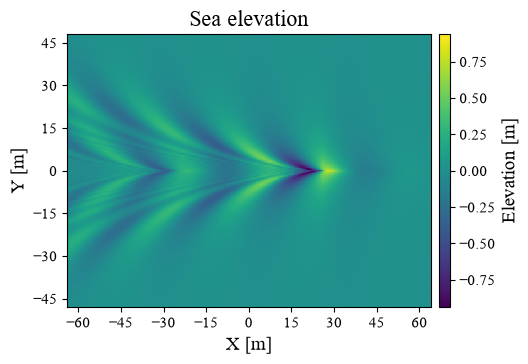

In [2]:
# surface
ship = ShipParameters(
    speed_mps=7.0,
    beam_m=5.9,
    length_m=52.0,
    draft_m=3.5,
)

plane_parameters = PlaneParameters(
    width_m=128.0,
    height_m=96.0,
    pixels_per_meter= 4,
    center_xy_m=(0.0, 0.0),
)

angular_parameters = AngularParameters(
    n_theta= 10000,
    start_angle_deg=0.0,
    cutoff_angle_deg=0.0,
)

base_plane = create_plane(
    width=plane_parameters.width_m,
    height=plane_parameters.height_m,
    pixels_per_meter=plane_parameters.pixels_per_meter,
    center_xy=plane_parameters.center_xy_m,
)

kelvin_spectrum = prepare_kelvin_spectrum(ship, angular_parameters)

snapshot_ship_xy_m = (0.0, 0.0)

surface_plane = simulate_plane(
    base_plane,
    ship_xy_m=snapshot_ship_xy_m,
    ship=ship,
    spectrum=kelvin_spectrum,
    quantity="elevation",
)

fig, ax, pcm = plot_plane(
    surface_plane
)

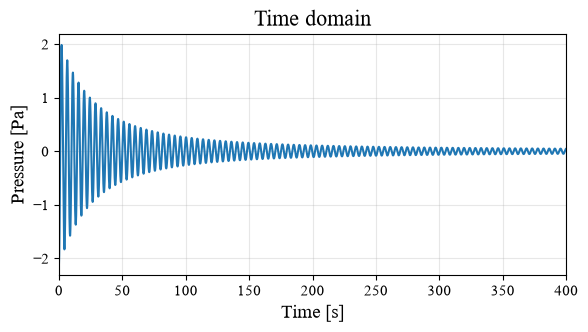

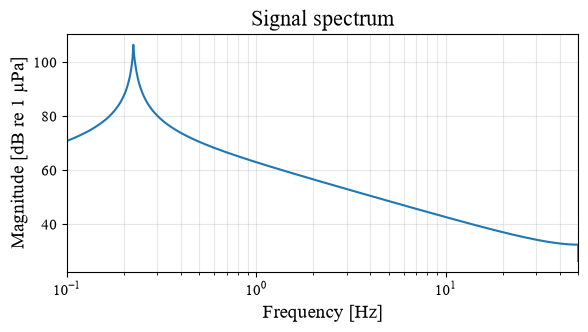

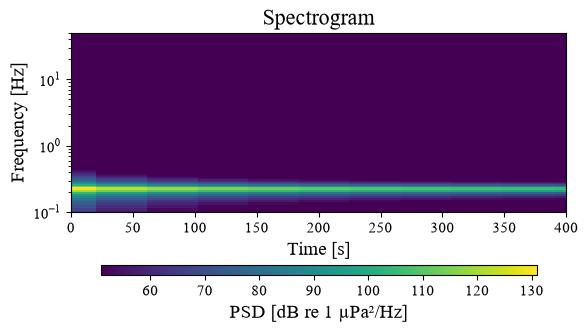

In [3]:
#pressure
receiver = ReceiverParameters(x_m=-40.0, y_m=-30.0, depth_m=10.0)
trajectory_start_xy_m = (400.0, 0.0)
duration_s = 500
sampling_frequency_hz = 100

time_s, receiver_pressure_pa, vessel_x_m, vessel_y_m = simulate_receiver(
    receiver,
    ship=ship,
    spectrum=kelvin_spectrum,
    trajectory_start_xy_m=trajectory_start_xy_m,
    duration_s=duration_s,
    sampling_frequency_hz=sampling_frequency_hz,
    water_depth_m = 15,
)

nperseg = 512*16
plot_signal_analysis(
    time_s,
    receiver_pressure_pa,
    sampling_frequency_hz,
    nperseg = nperseg,
    quantity="pressure",
    time_limits_s=(0, 400),
    frequency_limits_hz=(0.1, 100),
    save_path='αποτελεσματα/reference_freqshow'
)
plt.show()